# Detecção e segmentação de pluma de fumaça (CLIPSeg + SAM)
### Incêndio no terminal da Ultracargo (Santos-SP, abril de 2015)

**Disciplina:** Modelagem Computacional (UNIFESP)

**Alunos:** Bruno de Abreu Correia (RA 168522) e Lucas Apolinario de Oliveira (RA 163913)

Neste notebook a pluma é **detectada automaticamente** por um modelo de IA e depois segmentada com precisão pelo SAM:

1. O **CLIPSeg** recebe o texto `"black smoke plume"` e marca onde acha que está a fumaça (mapa grosso).
2. Dessa marcação saem uma **caixa** e um **ponto positivo** automáticos.
3. O **SAM** usa esses prompts e desenha a máscara com a borda bem ajustada.

Também testamos prompts manuais (um ponto, caixa, pontos e caixa + pontos positivos e negativos) para comparar com a detecção automática e avaliar o que a máscara pegou ou deixou de fora.

## 1. Ambiente e modelo

Ativar a GPU: *Ambiente de execução → Alterar tipo de ambiente de execução → GPU T4*.

In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git opencv-python matplotlib pandas transformers
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

  Preparing metadata (setup.py) ... done


In [2]:
import os
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

# vit_b é a versão mais leve do SAM
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device=device)
predictor = SamPredictor(sam)

os.makedirs("saidas", exist_ok=True)

Dispositivo: cuda


## 2. Carregando as fotos

In [3]:
from google.colab import drive
drive.mount("/content/drive")

# caminho da pasta com as 5 fotos no Drive
PASTA_IMGS = "/content/drive/MyDrive/Colab Notebooks/2026 2/Modelagem Computacional/Projeto Final/2 - Detecção e Segmentação de Pluma/imgs"
print(sorted(os.listdir(PASTA_IMGS)))

Mounted at /content/drive
['foto1.png', 'foto2.png', 'foto3.png', 'foto4.png', 'foto5.png']


Cada foto tem uma **caixa** (`box = [x0, y0, x1, y1]`), **pontos positivos** (dentro da fumaça) e **pontos negativos** (céu, nuvem, prédios), todos em pixels. Para achar essas coordenadas olhamos a grade da figura da próxima célula.

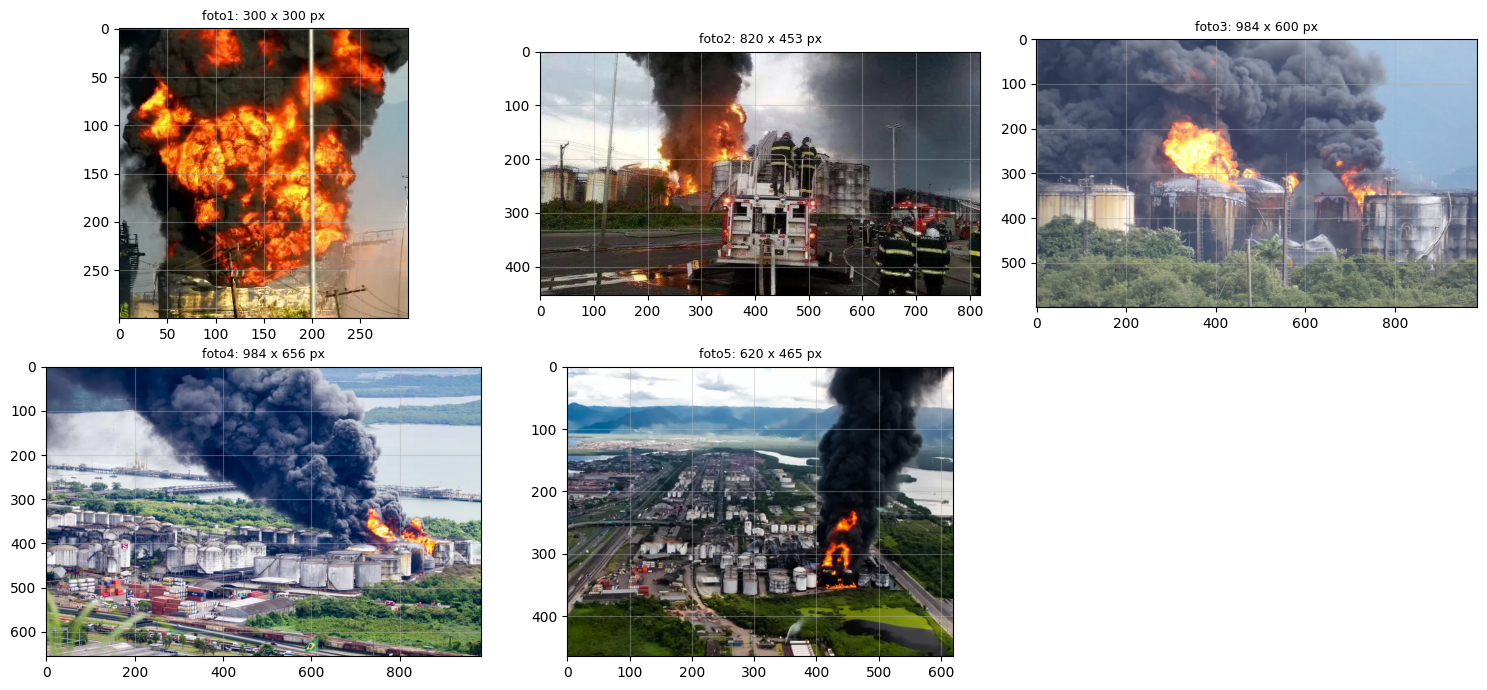

In [4]:
FOTOS = {
    "foto1": dict(arquivo="foto1.png",
                  box=[0, 0, 290, 268],
                  pos=[[60, 45], [150, 70], [28, 160], [275, 25]],
                  neg=[[285, 130], [8, 215], [150, 288]]),
    "foto2": dict(arquivo="foto2.png",
                  box=[165, 0, 402, 292],
                  pos=[[300, 40], [310, 100]],
                  neg=[[60, 100], [440, 60], [650, 100], [420, 340]]),
    "foto3": dict(arquivo="foto3.png",
                  box=[0, 0, 790, 340],
                  pos=[[250, 100], [600, 120], [720, 230], [100, 200]],
                  neg=[[880, 100], [880, 260], [100, 395], [300, 520]]),
    "foto4": dict(arquivo="foto4.png",
                  box=[0, 0, 810, 412],
                  pos=[[450, 100], [620, 200], [700, 290], [300, 60]],
                  neg=[[880, 200], [850, 100], [350, 440], [300, 330]]),
    "foto5": dict(arquivo="foto5.png",
                  box=[395, 0, 620, 355],
                  pos=[[470, 100], [450, 200], [430, 150]],
                  neg=[[250, 30], [200, 85], [580, 300], [580, 190], [300, 400], [607, 110]]),
}
MAX_LADO = 1280   # reduz fotos grandes para o SAM rodar mais rápido

IMAGENS = {}
for nome, cfg in FOTOS.items():
    bgr = cv2.imread(os.path.join(PASTA_IMGS, cfg["arquivo"]))
    img = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if max(h, w) > MAX_LADO:
        f = MAX_LADO / max(h, w)
        img = cv2.resize(img, (int(w * f), int(h * f)), interpolation=cv2.INTER_AREA)
    IMAGENS[nome] = img

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.ravel()
for ax, (nome, img) in zip(axes, IMAGENS.items()):
    ax.imshow(img); ax.grid(True, alpha=0.4)
    ax.set_title(f"{nome}: {img.shape[1]} x {img.shape[0]} px", fontsize=9)
axes[-1].axis("off")
plt.tight_layout(); plt.show()

## 3. Funções

- `segmentar`: roda o SAM com a caixa e/ou pontos. Pontos com label 1 são positivos (é pluma) e com label 0 são negativos (não é pluma).
- `mostrar`: mostra lado a lado a imagem original (com os prompts), a máscara binária e a máscara sobreposta.
- `posprocessar`: fecha buracos, remove ruído e fica só com o maior pedaço da máscara.

In [5]:
def segmentar(img, box=None, pts=None, labels=None):
    predictor.set_image(img)
    masks, scores, _ = predictor.predict(
        point_coords=None if pts is None else np.array(pts),
        point_labels=None if labels is None else np.array(labels),
        box=None if box is None else np.array(box),
        multimask_output=True,   # o SAM devolve 3 candidatas; ficamos com a de maior score
    )
    i = int(np.argmax(scores))
    return masks[i], float(scores[i])


def sobrepor(img, mask, cor=(255, 0, 0), alpha=0.5):
    out = img.copy().astype(float)
    out[mask] = (1 - alpha) * out[mask] + alpha * np.array(cor)
    return out.astype(np.uint8)


def contorno(img, mask, cor=(255, 0, 0), esp=3):
    out = img.copy()
    cs, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cs, -1, cor, esp)
    return out


def desenhar_prompts(ax, box=None, pts=None, labels=None):
    if box is not None:
        x0, y0, x1, y1 = box
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=2))
    if pts is not None:
        pts = np.array(pts); labels = np.array(labels)
        ax.scatter(pts[labels == 1, 0], pts[labels == 1, 1], c="lime", marker="*", s=200, edgecolor="white")
        ax.scatter(pts[labels == 0, 0], pts[labels == 0, 1], c="red", marker="X", s=150, edgecolor="white")


def mostrar(axs, img, mask, titulo, score, box=None, pts=None, labels=None):
    axs[0].imshow(img); desenhar_prompts(axs[0], box, pts, labels)
    axs[0].set_title(f"{titulo} | original + prompts")
    axs[1].imshow(mask, cmap="gray"); axs[1].set_title(f"Máscara binária (score {score:.3f})")
    axs[2].imshow(sobrepor(img, mask)); axs[2].set_title("Máscara sobreposta")
    for a in axs: a.axis("off")


def posprocessar(mask, k=15):
    m = mask.astype(np.uint8)
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, ker)   # fecha buracos
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, ker)    # tira ruído
    n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n > 1:
        m = (lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    return m.astype(bool)


RESULTADOS = {}

## 4. Experimentos

Para cada foto rodamos quatro configurações de prompt:

| Config. | Prompt |
|---|---|
| Inicial | 1 ponto positivo |
| A | só a caixa |
| B | só pontos positivos |
| C | caixa + pontos positivos + pontos negativos |

Depois pegamos a config. C e aplicamos o pós-processamento e o contorno (máscara final).

O *score* é a confiança do próprio SAM, não mede se a máscara está certa, então sempre conferimos a olho.

In [6]:
def rodar(nome):
    display(Markdown(f"### {nome}"))
    img = IMAGENS[nome]
    box, pos, neg = FOTOS[nome]["box"], FOTOS[nome]["pos"], FOTOS[nome]["neg"]
    pts_C = pos + neg
    lab_C = [1] * len(pos) + [0] * len(neg)

    configs = [
        ("Inicial (1 ponto)", dict(pts=[pos[0]], labels=[1])),
        ("A: caixa",          dict(box=box)),
        ("B: pontos +",       dict(pts=pos, labels=[1] * len(pos))),
        ("C: caixa + pontos +/-", dict(box=box, pts=pts_C, labels=lab_C)),
    ]

    fig, axs = plt.subplots(len(configs), 3, figsize=(15, 4.3 * len(configs)))
    res = {}
    for i, (titulo, kw) in enumerate(configs):
        m, s = segmentar(img, **kw)
        mostrar(axs[i], img, m, titulo, s, **kw)
        res[titulo] = dict(mask=m, score=s, area_pct=100 * m.mean())
    plt.tight_layout(); plt.show()

    # máscara final: config. C + pós-processamento
    mC = res["C: caixa + pontos +/-"]["mask"]
    mF = posprocessar(mC)
    res["Final (C + pós-proc.)"] = dict(mask=mF, score=res["C: caixa + pontos +/-"]["score"], area_pct=100 * mF.mean())

    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].imshow(img); ax[0].set_title("Original")
    ax[1].imshow(mF, cmap="gray"); ax[1].set_title("Máscara final")
    ax[2].imshow(contorno(img, mF)); ax[2].set_title("Contorno sobre a imagem")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

    cv2.imwrite(f"saidas/{nome}_mascara_final.png", (mF * 255).astype(np.uint8))
    cv2.imwrite(f"saidas/{nome}_sobreposicao_final.png", cv2.cvtColor(sobrepor(img, mF), cv2.COLOR_RGB2BGR))

    RESULTADOS[nome] = res
    display(pd.DataFrame({k: {"score SAM": round(r["score"], 3), "área (%)": round(r["area_pct"], 2)}
                          for k, r in res.items()}).T)

In [7]:
rodar("foto1")

Output hidden; open in https://colab.research.google.com to view.

### Análise: foto1

Na config. C a máscara cobre a fumaça preta do topo e das laterais, mas **também engloba a bola de fogo**. A região laranja ficou com vários buraquinhos na máscara. Os postes e os tanques da base ficaram de fora, como queríamos. A coluna grossa de fumaça do lado direito, depois do poste, foi incluída. Esta foto é a mais difícil: a imagem é pequena (300x300), o fogo e a fumaça estão misturados e o poste branco divide a cena em duas partes. O SAM segmenta por borda e cor, então trata o fogo como parte do mesmo objeto.

### foto2

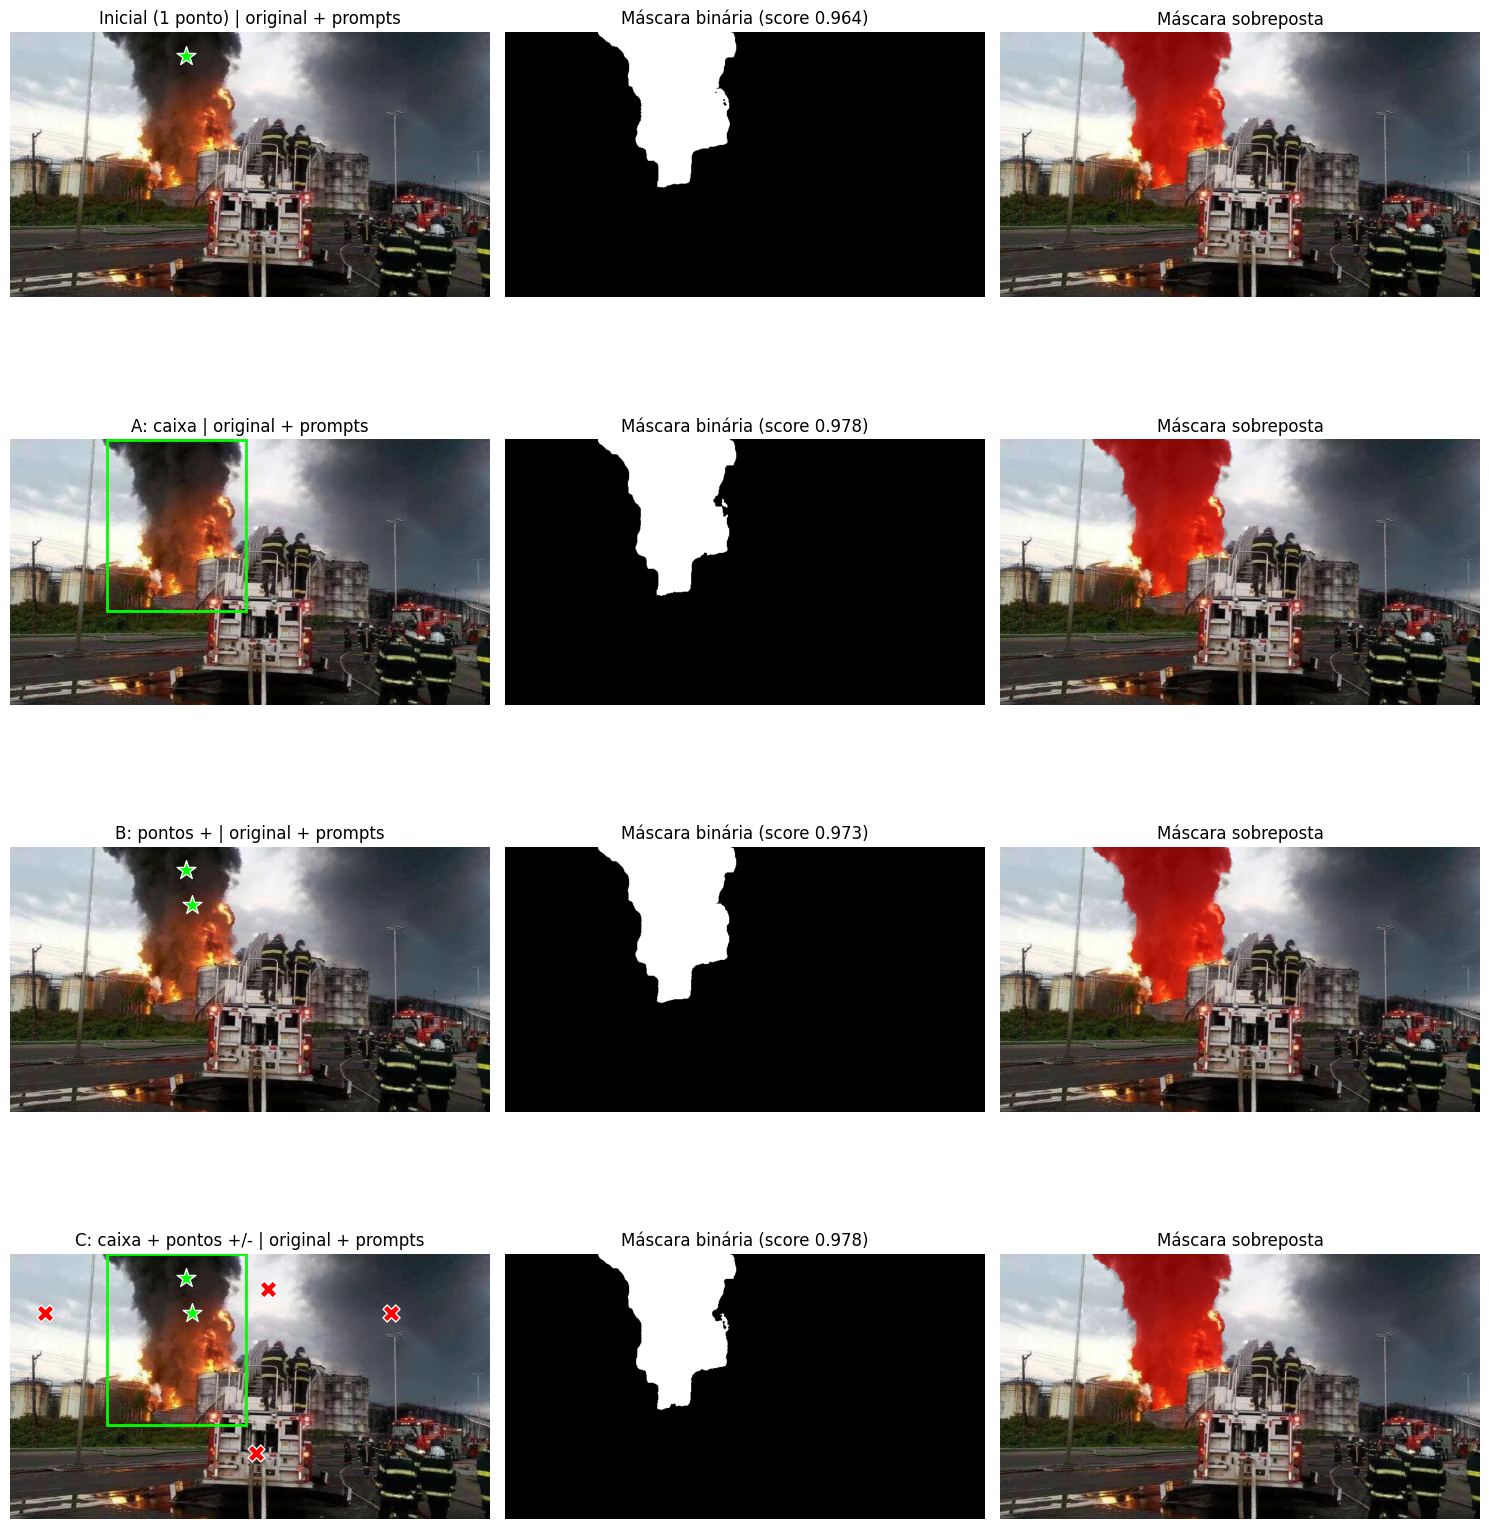

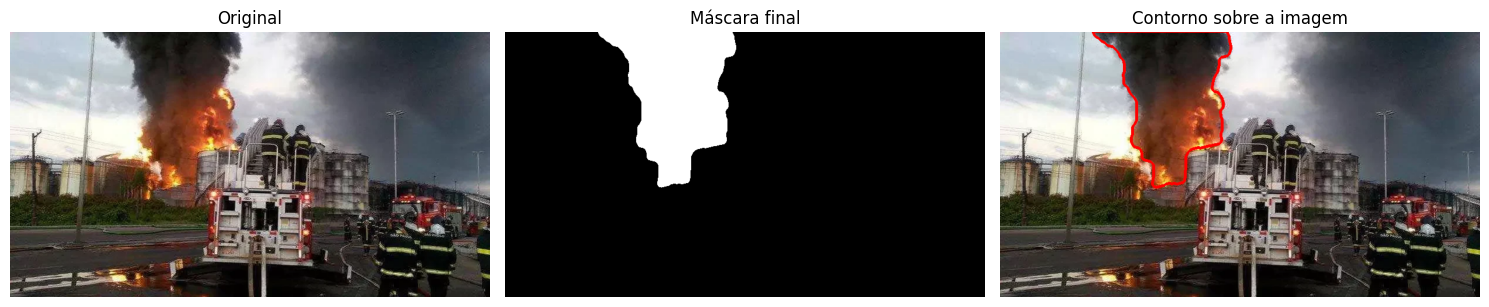

,score SAM,área (%)
Inicial (1 ponto),0.964,10.04
A: caixa,0.978,9.93
B: pontos +,0.973,10.05
C: caixa + pontos +/-,0.978,9.86
Final (C + pós-proc.),0.978,9.95


In [8]:
rodar("foto2")

### Análise: foto2

A máscara da config. C pegou bem a coluna escura que sobe do fogo, com a borda bem seguida contra o céu claro. O fogo da base ficou em parte de fora e os bombeiros e o caminhão não entraram. O que ficou de fora foi a massa cinza grande do lado direito: ela é parecida com nuvem de tempestade e não está dentro da caixa que desenhamos, então a máscara cobre só uma das duas plumas da foto. A iluminação difícil aqui é o céu claro atrás da fumaça misturado com a luz alaranjada das chamas.

### foto3

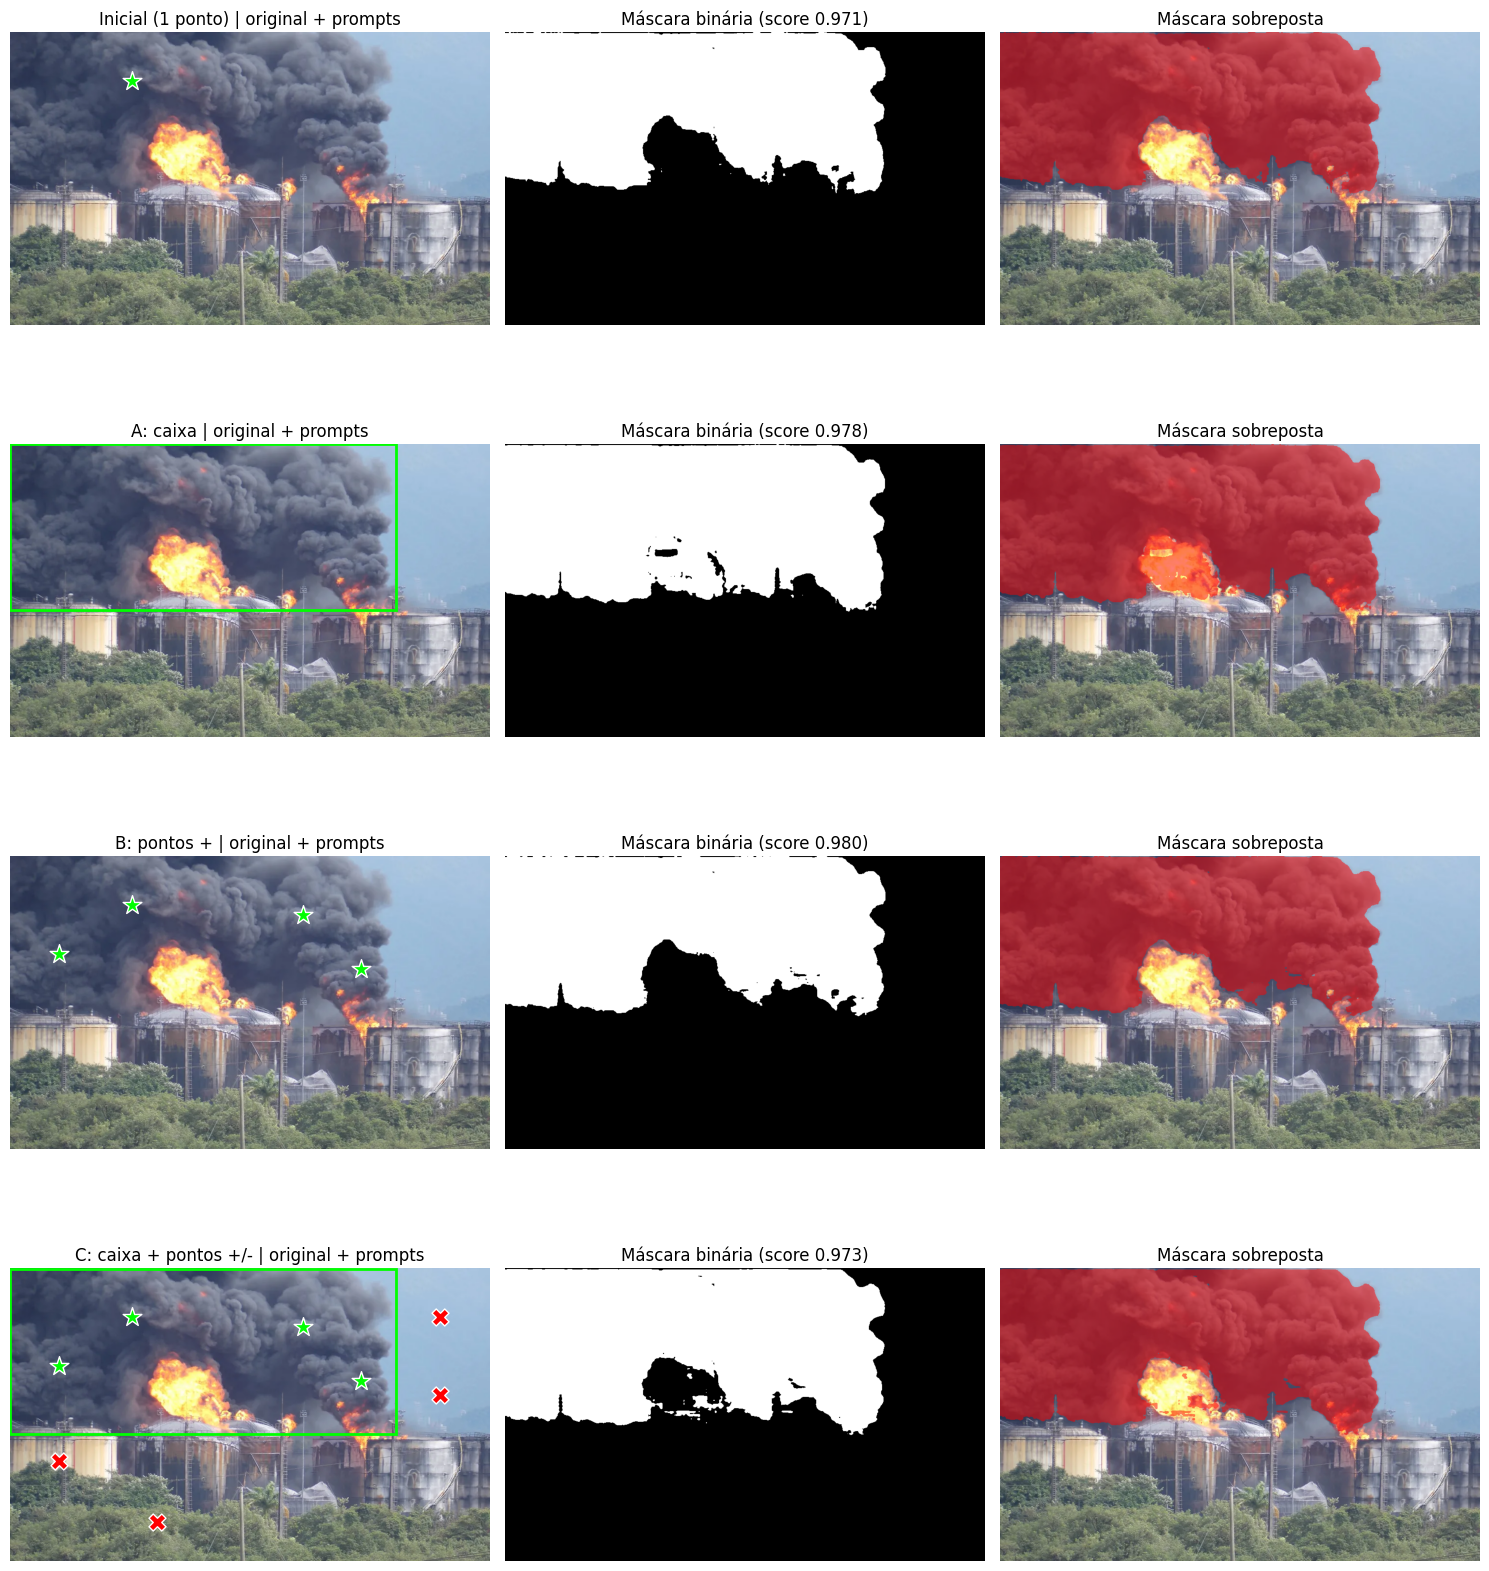

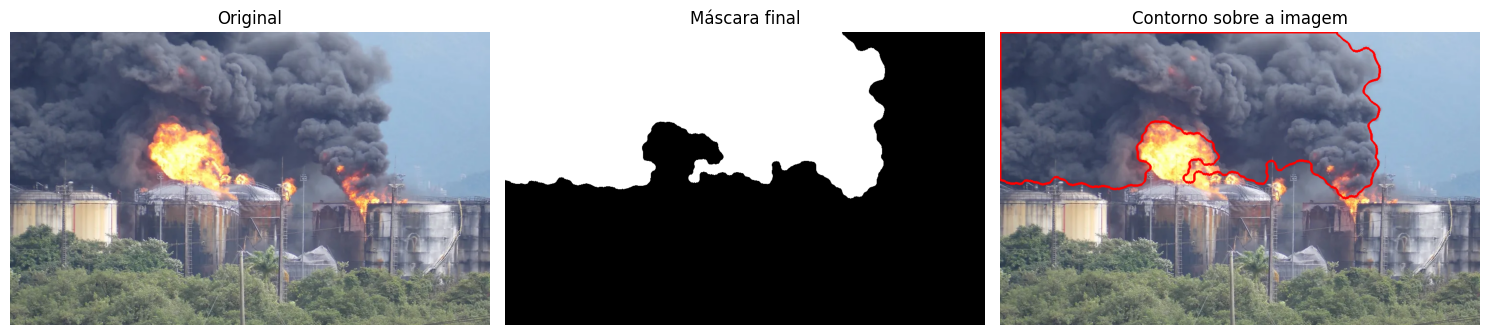

,score SAM,área (%)
Inicial (1 ponto),0.971,35.77
A: caixa,0.978,39.06
B: pontos +,0.980,35.43
C: caixa + pontos +/-,0.973,36.40
Final (C + pós-proc.),0.973,36.90


In [9]:
rodar("foto3")

### Análise: foto3

Foi um dos melhores resultados. A fumaça cinza-escura contra o céu azul tem bastante contraste, e a máscara seguiu bem as bordas "cheias de bolhas" da pluma. A bola de fogo ficou como um buraco na máscara, ou seja, o SAM não colocou o fogo junto com a fumaça aqui, diferente da foto1. Os tanques e a vegetação não entraram. Um ponto a observar é a borda direita, onde a fumaça é mais fina e o corte é um pouco artificial.

In [10]:
rodar("foto4")

Output hidden; open in https://colab.research.google.com to view.

### Análise: foto4

A máscara cobre a pluma inteira, do fogo até o canto superior esquerdo, e deixa o fogo de fora. Contra a água e o céu claro o contorno ficou bom. O problema está no canto superior esquerdo: lá a fumaça vai ficando fina e se mistura com a névoa e as nuvens, sem borda clara, e a máscara vai até o canto da imagem sem dar para saber onde a pluma realmente termina. Na parte de baixo, as fumaças menores perto do fogo foram incluídas.

In [11]:
rodar("foto5")

Output hidden; open in https://colab.research.google.com to view.

### Análise: foto5

Foto de ângulo mais alto, com a coluna quase vertical (vento fraco). A máscara pegou a coluna toda, do topo da imagem até a base, com borda limpa contra o céu e as montanhas. Dessa vez o fogo da base **entrou** na máscara (ficou com a cor avermelhada por cima), como na foto1. A pluma é bem escura e isolada do resto da cena, o que ajudou. As estruturas da refinaria ao fundo não foram incluídas.

## 5. Detecção automática: CLIPSeg + SAM

O **CLIPSeg** é um modelo que segmenta a partir de um texto: ele devolve, para cada pixel, a probabilidade de pertencer ao que foi descrito (`PROMPT_TEXTO`). Pixels acima do `LIMIAR` viram a máscara semântica. Essa máscara é grossa (o modelo trabalha em baixa resolução), então usamos ela só para gerar a **caixa** e o **ponto positivo** que o SAM recebe, sem precisarmos desenhar nada à mão.

In [12]:
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation
from PIL import Image

proc_clip = CLIPSegProcessor.from_pretrained("CIDAS/clipseg-rd64-refined")
clipseg = CLIPSegForImageSegmentation.from_pretrained("CIDAS/clipseg-rd64-refined").to(device).eval()

PROMPT_TEXTO = "black smoke plume"
LIMIAR = 0.4   # probabilidade mínima para contar como fumaça


def mascara_clipseg(img):
    inp = proc_clip(text=[PROMPT_TEXTO], images=[Image.fromarray(img)], return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        logits = clipseg(**inp).logits
    prob = torch.sigmoid(logits).squeeze().cpu().numpy()
    prob = cv2.resize(prob, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
    return prob > LIMIAR


def caixa_da_mascara(mask, margem=0.03):
    ys, xs = np.where(mask)
    H, W = mask.shape
    mx, my = int(W * margem), int(H * margem)
    return [max(xs.min() - mx, 0), max(ys.min() - my, 0), min(xs.max() + mx, W - 1), min(ys.max() + my, H - 1)]


def ponto_interno(mask):
    # ponto mais "fundo" dentro da máscara
    d = cv2.distanceTransform(mask.astype(np.uint8), cv2.DIST_L2, 5)
    y, x = np.unravel_index(np.argmax(d), d.shape)
    return [int(x), int(y)]


def iou(a, b):
    return float(np.logical_and(a, b).sum() / np.logical_or(a, b).sum())

preprocessor_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.73k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/974 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  603MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/462 [00:00<?, ?it/s]

In [13]:
AUTO = {}
linhas = []

for nome, img in IMAGENS.items():
    m_clip = mascara_clipseg(img)
    m_base = posprocessar(m_clip, k=9)          # só o maior pedaço, para a caixa ficar limpa
    if m_base.sum() == 0:
        m_base = m_clip
    box_auto = caixa_da_mascara(m_base)
    pt_auto = ponto_interno(m_base)
    m_auto, s_auto = segmentar(img, box=box_auto, pts=[pt_auto], labels=[1])
    m_manual = RESULTADOS[nome]["C: caixa + pontos +/-"]["mask"]

    fig, ax = plt.subplots(1, 4, figsize=(22, 5))
    ax[0].imshow(img); ax[0].set_title("Original")
    ax[1].imshow(sobrepor(img, m_clip, cor=(0, 120, 255))); ax[1].set_title("CLIPSeg")
    ax[2].imshow(sobrepor(img, m_manual)); ax[2].set_title("SAM, config. C (prompts manuais)")
    ax[3].imshow(sobrepor(img, m_auto, cor=(0, 200, 0))); desenhar_prompts(ax[3], box_auto, [pt_auto], [1])
    ax[3].set_title(f"CLIPSeg + SAM (score {s_auto:.3f})")
    for a in ax: a.axis("off")
    plt.suptitle(nome, fontsize=14); plt.tight_layout(); plt.show()

    AUTO[nome] = m_auto
    cv2.imwrite(f"saidas/{nome}_mascara_clipseg_sam.png", (m_auto * 255).astype(np.uint8))
    linhas.append(dict(foto=nome, area_clipseg=round(100 * m_clip.mean(), 2),
                       area_manual=round(100 * m_manual.mean(), 2), area_auto=round(100 * m_auto.mean(), 2),
                       IoU_auto_vs_manual=round(iou(m_auto, m_manual), 3)))

display(pd.DataFrame(linhas).set_index("foto"))

Output hidden; open in https://colab.research.google.com to view.

### Análise: detecção automática

- **foto1:** é a que mais falhou. O CLIPSeg marcou só partes da fumaça preta (topo e lado esquerdo) e deixou de fora o fogo e a coluna da direita, então a caixa automática ficou só no canto superior esquerdo e o SAM segmentou apenas essa parte. A prompt manual (config. C) cobriu bem mais da pluma.
- **foto2:** o CLIPSeg achou a coluna da esquerda e o SAM ajustou bem a borda. A massa cinza da direita não foi marcada, como na config. C.
- **foto3:** o CLIPSeg pegou a fumaça toda, mas com bordas "quadradas" e grossas. O SAM corrigiu e seguiu o contorno das nuvens de fumaça, deixando a bola de fogo de fora.
- **foto4:** o CLIPSeg pegou a pluma inteira, incluindo um pedaço da névoa do canto superior esquerdo. O SAM deixou a borda mais precisa, mas manteve essa região.
- **foto5:** o CLIPSeg achou a coluna e o SAM refinou a borda. O fogo da base entrou na máscara.
- **No geral:** o CLIPSeg sozinho acha onde está a fumaça mas com bordas grossas (blocos), e o SAM sozinho tem borda boa mas precisa de prompt. Juntos funcionam sem desenhar nada à mão em 4 das 5 fotos. A qualidade da caixa automática decide o resultado: se o CLIPSeg marca só um pedaço (foto1), o SAM também fica com só um pedaço.

## 6. Resumo entre as fotos

**Área da máscara (% da imagem)**

foto,foto1,foto2,foto3,foto4,foto5
config,,,,,
A: caixa,65.54,9.93,39.06,25.23,13.76
B: pontos +,61.51,10.05,35.43,25.18,13.66
C: caixa + pontos +/-,59.12,9.86,36.40,25.83,13.42
Final (C + pós-proc.),62.00,9.95,36.90,26.31,13.53
Inicial (1 ponto),22.03,10.04,35.77,15.13,13.64


**Score do SAM**

foto,foto1,foto2,foto3,foto4,foto5
config,,,,,
A: caixa,0.956,0.978,0.978,0.981,0.980
B: pontos +,0.950,0.973,0.980,0.975,0.978
C: caixa + pontos +/-,0.952,0.978,0.973,0.968,0.962
Final (C + pós-proc.),0.952,0.978,0.973,0.968,0.962
Inicial (1 ponto),0.873,0.964,0.971,0.934,0.956


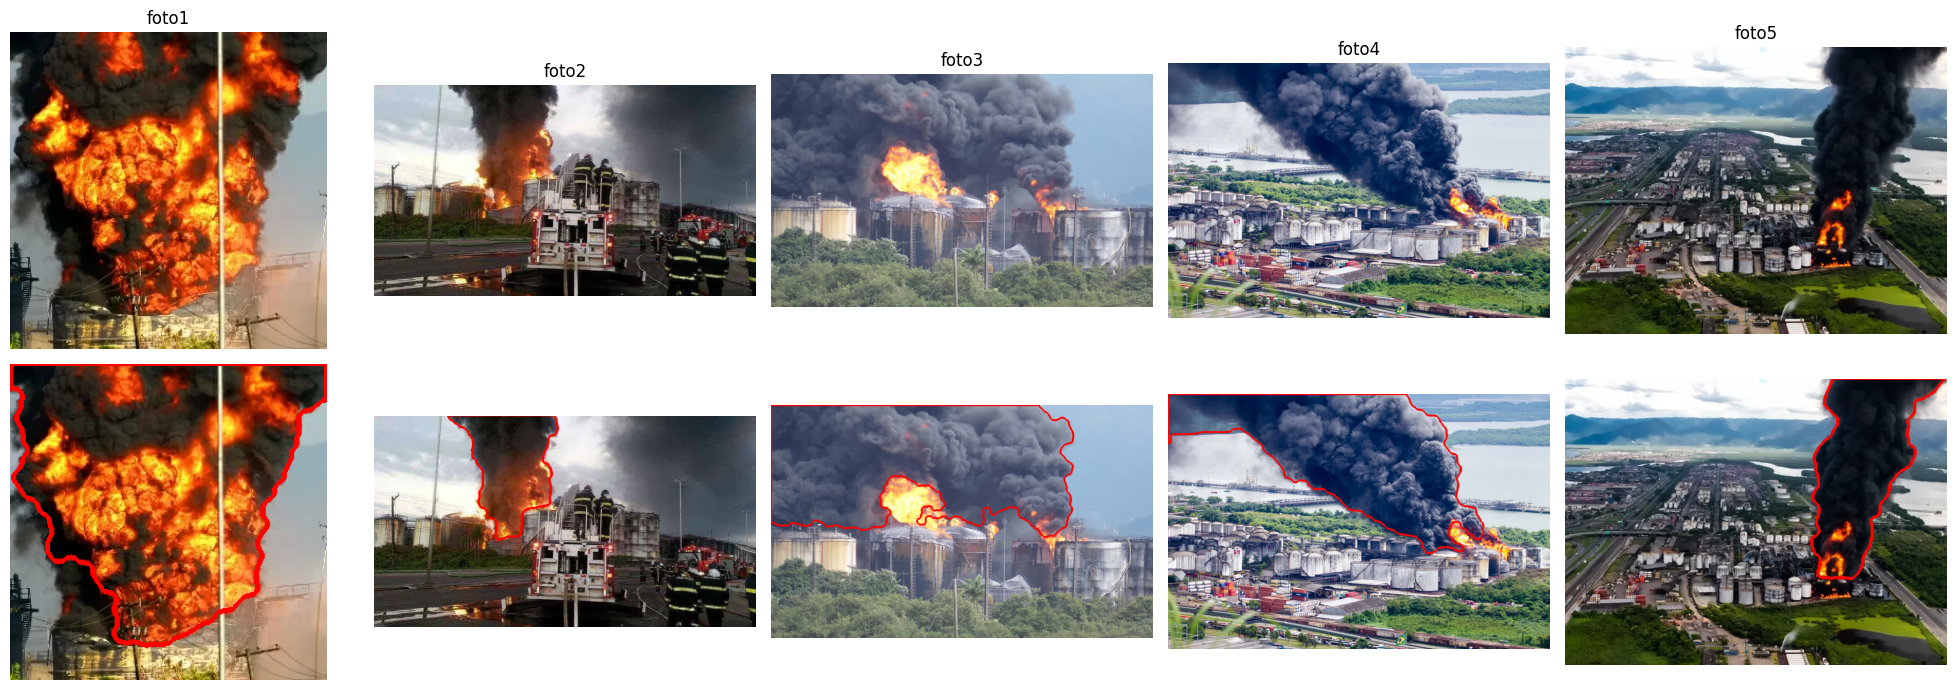

In [14]:
linhas = []
for nome, res in RESULTADOS.items():
    for cfg, r in res.items():
        linhas.append(dict(foto=nome, config=cfg, score=round(r["score"], 3), area_pct=round(r["area_pct"], 2)))
df = pd.DataFrame(linhas)

display(Markdown("**Área da máscara (% da imagem)**"))
display(df.pivot(index="config", columns="foto", values="area_pct"))
display(Markdown("**Score do SAM**"))
display(df.pivot(index="config", columns="foto", values="score"))

fig, ax = plt.subplots(2, 5, figsize=(20, 7))
for j, n in enumerate(RESULTADOS):
    ax[0, j].imshow(IMAGENS[n]); ax[0, j].set_title(n)
    ax[1, j].imshow(contorno(IMAGENS[n], RESULTADOS[n]["Final (C + pós-proc.)"]["mask"]))
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.tight_layout(); plt.show()

## 7. Discussão

**A máscara cobre a pluma? Inclui o que não é pluma? Deixa partes de fora?**
Nas 5 fotos a config. C cobriu bem o corpo principal da pluma. O que não pertence à pluma entrou de duas formas: o fogo, nas fotos 1 e 5 (nas fotos 3 e 4 ficou de fora), e a névoa do canto da foto 4, onde a fumaça se dilui. O que ficou de fora foi, na foto 2, a segunda massa de fumaça à direita.

**Prompts.** Em geral um ponto só (inicial) tende a pegar só um pedaço da fumaça, porque o SAM escolhe o "objeto" mais provável em volta do ponto. A caixa sozinha limita a região, mas pode puxar o que estiver dentro dela. Os pontos negativos servem para tirar céu, nuvem e prédios. Foi por isso que usamos a config. C como base da máscara final. *(Conferir essa comparação nas figuras de cada foto quando rodar.)*

**Iluminação.** Na foto 2 o céu claro atrás da pluma e a luz laranja do fogo atrapalham a leitura das bordas. Nas fotos 3, 4 e 5 a fumaça escura contra o céu claro foi o melhor caso.

**Contraste.** O contraste alto (fumaça escura e céu claro) deixa a borda nítida e o SAM acerta. Onde a fumaça fica fina e cinza (canto da foto 4, borda direita da foto 3) o contraste cai e a máscara fica imprecisa.

**Semelhança com nuvens.** Na foto 2 a massa cinza da direita parece nuvem de tempestade e é difícil dizer se é fumaça. O SAM não sabe o que é fumaça, só segmenta regiões por forma e borda, então quem decide o que é pluma somos nós, pelos prompts.

**Detecção automática.** O CLIPSeg sabe o que é "fumaça" pelo texto, o SAM não. Na foto 2 o CLIPSeg também ignorou a massa cinza da direita, o que mostra que ele separa a pluma melhor das nuvens do que um prompt sem sentido, mas ele não é perfeito: na foto 1 a fumaça misturada com fogo confundiu o modelo e a caixa automática ficou pequena. A fumaça que se dilui (foto 4) também foi marcada até a névoa.

**Fogo.** Fogo e fumaça aparecem juntos e o SAM ora junta (fotos 1 e 5), ora separa (fotos 3 e 4). Isso depende dos pontos e da caixa que damos.

**Outros elementos.** O poste da foto 1 divide a fumaça em duas partes, e os tanques e o caminhão de bombeiros ficaram de fora das máscaras por causa dos pontos negativos.

**Bordas transparentes.** A pluma é semitransparente e vai sumindo aos poucos, mas a máscara binária impõe um corte seco.

## 8. Conclusão

- O pipeline **CLIPSeg + SAM** detectou a pluma automaticamente em 4 das 5 fotos, com borda tão boa quanto a dos prompts manuais. Na foto 1 (fogo misturado com fumaça) os prompts manuais foram melhores.
- Entre os prompts manuais, a melhor configuração foi a **C (caixa + pontos positivos e negativos)**, porque a caixa limita a região e os pontos negativos evitam que a máscara vaze para céu, nuvens e construções.
- O pós-processamento ajudou a fechar buracos (principalmente onde há fogo dentro da máscara) e o contorno deixa mais fácil ver se a borda está correta.
- As maiores dificuldades foram: fogo misturado com a fumaça, fumaça fina que se confunde com névoa e nuvem, e a foto pequena (foto 1).
- Como o SAM não "entende" o que é fumaça, o resultado depende bastante dos prompts que escolhemos à mão para cada foto.
- A máscara dá o formato observado da pluma, que pode ser comparado com a pluma simulada pelo modelo de difusão-advecção do nosso estudo de caso.